Training RL policy (~20s)...
RL Training complete in 2.9 s
Thermostat Peak T_chip: 87.52 °C (Limit: 85.0 °C)
Python MPC Peak T_chip: 77.90 °C (Limit: 85.0 °C)
RL Policy  Peak T_chip: 78.79 °C (Limit: 85.0 °C)


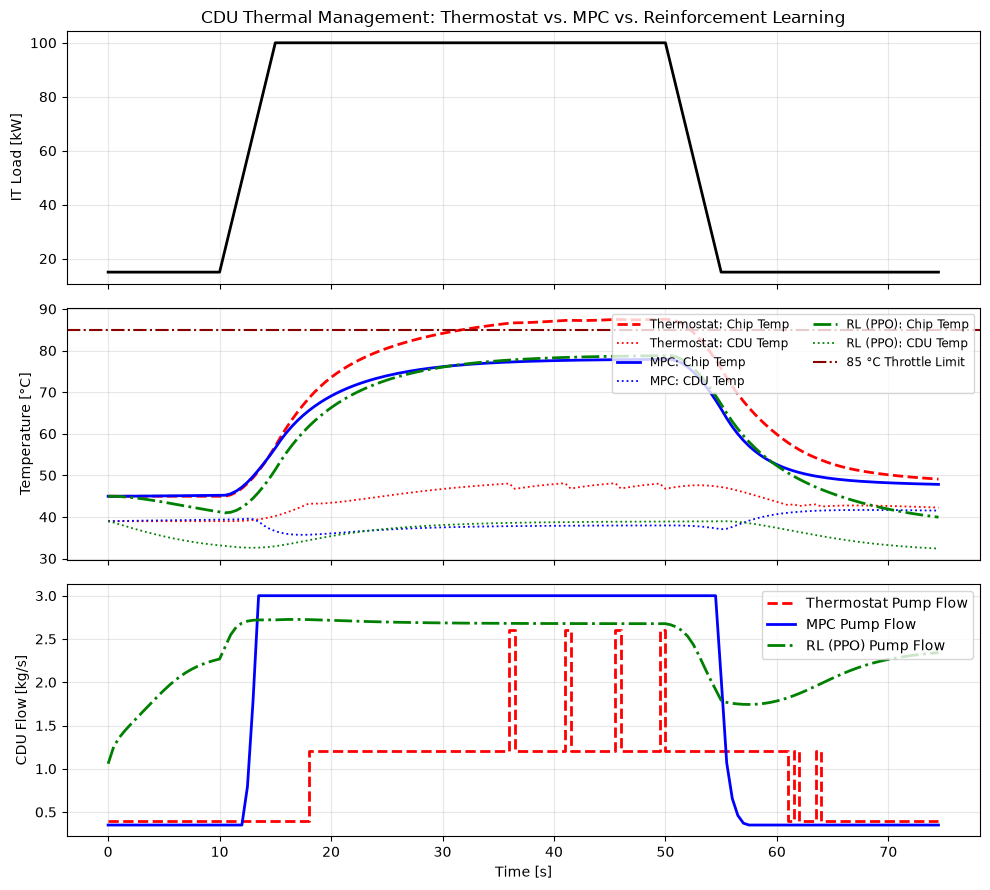

In [1]:
import time
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt

np.random.seed(42)

# ==============================================================================
# 1. Physical Parameters (Matching Your Notebook Settings)
# ==============================================================================
C_chip = 12.0      # kJ/K  (silicon + copper cold plates)
C_cdu  = 35.0      # kJ/K  (~8.5 L secondary coolant + HX thermal mass)
R_th   = 0.40      # K/kW  (chip-to-coolant thermal resistance)
cp     = 4.18      # kJ/(kg*K) (water/glycol specific heat)
T_fac  = 30.0      # degC  (warm facility water supply, ASHRAE W3)
T_throttle = 85.0  # degC  (chip thermal throttling limit)
T_soft_cap = 60.0  # degC  (safety buffer below throttling)

m_min, m_max = 0.35, 3.0  # kg/s (CDU VFD pump flow rate bounds)

def cdu_ode(x, u_mdot, q_it):
    """Nonlinear 2-state CDU + cold-plate energy balance."""
    T_chip, T_cdu = x
    q_conv = (T_chip - T_cdu) / R_th
    dT_chip = (q_it - q_conv) / C_chip
    dT_cdu  = (q_conv - u_mdot * cp * (T_cdu - T_fac)) / C_cdu
    return np.array([dT_chip, dT_cdu])

def rk4_step(x, u, q_it, dt):
    """4th-order Runge-Kutta plant integration."""
    k1 = cdu_ode(x, u, q_it)
    k2 = cdu_ode(x + 0.5 * dt * k1, u, q_it)
    k3 = cdu_ode(x + 0.5 * dt * k2, u, q_it)
    k4 = cdu_ode(x + dt * k3, u, q_it)
    return x + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

# ==============================================================================
# 2. Simulation Setup & 5-Second Surge Profile
# ==============================================================================
dt = 0.5
T_sim = 75.0
N_steps = int(T_sim / dt)
t_grid = np.arange(N_steps) * dt

u_idle = 0.4
T_cdu0 = T_fac + 15.0 / (u_idle * cp)
T_chip0 = T_cdu0 + 15.0 * R_th
x0 = np.array([T_chip0, T_cdu0])

q_profile = np.zeros(N_steps)
for k, t in enumerate(t_grid):
    if t < 10.0:
        q_profile[k] = 15.0
    elif t < 15.0:
        q_profile[k] = 15.0 + 85.0 * (t - 10.0) / 5.0
    elif t < 50.0:
        q_profile[k] = 100.0
    elif t < 55.0:
        q_profile[k] = 100.0 - 85.0 * (t - 50.0) / 5.0
    else:
        q_profile[k] = 15.0

# ==============================================================================
# 3. Controller A: Classical 3-Stage Thermostat
# ==============================================================================
x_therm = x0.copy()
hist_therm = np.zeros((N_steps, 3))  # [T_chip, T_cdu, m_dot]

for k in range(N_steps):
    T_cdu_meas = x_therm[1]
    if T_cdu_meas < 43.0:
        u_curr = 0.4
    elif T_cdu_meas < 48.0:
        u_curr = 1.2
    else:
        u_curr = 2.6
    hist_therm[k] = [x_therm[0], x_therm[1], u_curr]
    x_therm = rk4_step(x_therm, u_curr, q_profile[k], dt)

# ==============================================================================
# 4. Controller B: Successive-Linearization MPC
# ==============================================================================
Np = 16
x_mpc = x0.copy()
hist_mpc = np.zeros((N_steps, 3))
u_prev = u_idle

for k in range(N_steps):
    q_curr = q_profile[k]
    f0 = cdu_ode(x_mpc, u_prev, q_curr)
    A_c = np.array([
        [-1.0 / (C_chip * R_th),  1.0 / (C_chip * R_th)],
        [ 1.0 / (C_cdu * R_th),  -(1.0 / (C_cdu * R_th) + u_prev * cp / C_cdu)]
    ])
    B_u = np.array([0.0, -cp * (x_mpc[1] - T_fac) / C_cdu])
    B_d = np.array([1.0 / C_chip, 0.0])
    c_0 = f0 - A_c @ x_mpc - B_u * u_prev - B_d * q_curr

    Ad = np.eye(2) + dt * A_c
    Bu_d = dt * B_u
    Bd_d = dt * B_d
    cd_d = dt * c_0

    def mpc_objective(u_seq):
        x_pred = x_mpc.copy()
        cost = 0.0
        u_last = u_prev
        for j in range(Np):
            u_j = u_seq[j]
            x_pred = Ad @ x_pred + Bu_d * u_j + Bd_d * q_curr + cd_d
            violation = max(0.0, x_pred[0] - T_soft_cap)
            cost += 100.0 * (violation ** 2) + 1.0 * (u_j ** 3) + 3.0 * ((u_j - u_last) ** 2)
            u_last = u_j
        return cost

    res = minimize(
        mpc_objective,
        x0=np.full(Np, u_prev),
        method="L-BFGS-B",
        bounds=[(m_min, m_max)] * Np,
        options={"maxiter": 40}
    )
    u_opt = res.x[0]
    hist_mpc[k] = [x_mpc[0], x_mpc[1], u_opt]
    x_mpc = rk4_step(x_mpc, u_opt, q_curr, dt)
    u_prev = u_opt

# ==============================================================================
# 5. Controller C: Pure-NumPy Reinforcement Learning (PPO)
# ==============================================================================
class CDUEnv:
    def __init__(self):
        self.N_steps = N_steps
        self.reset()

    def _sample_workload(self):
        t_start = np.random.uniform(5.0, 20.0)
        ramp_up = np.random.uniform(3.0, 8.0)
        hold_dur = np.random.uniform(20.0, 40.0)
        ramp_dn = np.random.uniform(3.0, 8.0)
        q_idle = np.random.uniform(10.0, 25.0)
        q_peak = np.random.uniform(70.0, 110.0)
        q = np.full(self.N_steps, q_idle)
        for k, t in enumerate(t_grid):
            if t_start <= t < t_start + ramp_up:
                q[k] = q_idle + (q_peak - q_idle) * (t - t_start) / ramp_up
            elif t_start + ramp_up <= t < t_start + ramp_up + hold_dur:
                q[k] = q_peak
            elif t_start + ramp_up + hold_dur <= t < t_start + ramp_up + hold_dur + ramp_dn:
                q[k] = q_peak - (q_peak - q_idle) * (t - (t_start + ramp_up + hold_dur)) / ramp_dn
        return q

    def reset(self, fixed_profile=None):
        self.q_profile = self._sample_workload() if fixed_profile is None else fixed_profile
        self.k = 0
        self.u_prev = u_idle
        q0 = self.q_profile[0]
        T_cdu0 = T_fac + q0 / (self.u_prev * cp)
        T_chip0 = T_cdu0 + q0 * R_th
        self.x = np.array([T_chip0, T_cdu0])
        return self._get_obs()

    def _get_obs(self):
        q_curr = self.q_profile[self.k]
        return np.array([
            (self.x[0] - 55.0) / 30.0,
            (self.x[1] - 45.0) / 20.0,
            (q_curr - 50.0) / 50.0,
            (self.u_prev - 1.5) / 1.5
        ])

    def step(self, action_norm):
        a = float(np.clip(action_norm, -1.0, 1.0))
        u = m_min + 0.5 * (a + 1.0) * (m_max - m_min)
        state_before = self.x.copy()
        q_curr = self.q_profile[self.k]
        self.x = rk4_step(self.x, u, q_curr, dt)

        violation = max(0.0, self.x[0] - T_soft_cap)
        stage_cost = 250.0 * (violation ** 2) + 1.0 * (u ** 3) + 3.0 * ((u - self.u_prev) ** 2)
        reward = -0.02 * stage_cost

        self.u_prev = u
        self.k += 1
        done = (self.k >= self.N_steps)
        next_obs = self._get_obs() if not done else np.zeros(4)
        return next_obs, reward, done, {"T_chip": state_before[0], "T_cdu": state_before[1], "u": u}

class NumpyMLP:
    def __init__(self, in_dim, hid_dim, out_dim, tanh_out=False):
        self.W1 = np.random.randn(in_dim, hid_dim) * np.sqrt(2.0 / in_dim)
        self.b1 = np.zeros(hid_dim)
        self.W2 = np.random.randn(hid_dim, hid_dim) * np.sqrt(2.0 / hid_dim)
        self.b2 = np.zeros(hid_dim)
        self.W3 = np.random.randn(hid_dim, out_dim) * 0.1
        self.b3 = np.zeros(out_dim)
        self.tanh_out = tanh_out
        self.params = [self.W1, self.b1, self.W2, self.b2, self.W3, self.b3]
        self.m = [np.zeros_like(p) for p in self.params]
        self.v = [np.zeros_like(p) for p in self.params]
        self.t = 0

    def forward(self, X):
        h1 = np.tanh(X @ self.W1 + self.b1)
        h2 = np.tanh(h1 @ self.W2 + self.b2)
        z3 = h2 @ self.W3 + self.b3
        out = np.tanh(z3) if self.tanh_out else z3
        return out, (X, h1, h2, out)

    def backward_step(self, d_out, cache, lr=1e-3):
        X, h1, h2, out = cache
        N = X.shape[0]
        dz3 = d_out * (1.0 - out**2) if self.tanh_out else d_out
        dW3 = (h2.T @ dz3) / N; db3 = dz3.mean(axis=0)
        dh2 = dz3 @ self.W3.T
        dz2 = dh2 * (1.0 - h2**2)
        dW2 = (h1.T @ dz2) / N; db2 = dz2.mean(axis=0)
        dh1 = dz2 @ self.W2.T
        dz1 = dh1 * (1.0 - h1**2)
        dW1 = (X.T @ dz1) / N; db1 = dz1.mean(axis=0)

        self.t += 1
        for i, (p, g) in enumerate(zip(self.params, [dW1, db1, dW2, db2, dW3, db3])):
            g = np.clip(g, -1.0, 1.0)
            self.m[i] = 0.9 * self.m[i] + 0.1 * g
            self.v[i] = 0.999 * self.v[i] + 0.001 * (g**2)
            p -= lr * (self.m[i] / (1.0 - 0.9**self.t)) / (np.sqrt(self.v[i] / (1.0 - 0.999**self.t)) + 1e-8)

print("Training RL policy")
t0 = time.time()
env = CDUEnv()
actor = NumpyMLP(4, 48, 1, tanh_out=True)
critic = NumpyMLP(4, 48, 1, tanh_out=False)
gamma, lam, clip_eps = 0.99, 0.95, 0.2

for epoch in range(70):
    std = 0.45 - 0.30 * (epoch / 70.0)
    obs_buf, act_buf, logp_buf, ret_buf, adv_buf = [], [], [], [], []
    for _ in range(8):
        obs = env.reset()
        ep_obs, ep_act, ep_logp, ep_rew, ep_val = [], [], [], [], []
        done = False
        while not done:
            mean, _ = actor.forward(obs[None, :])
            val, _ = critic.forward(obs[None, :])
            m_val = mean[0, 0]
            act = m_val + std * np.random.randn()
            logp = -0.5 * (((act - m_val) / std)**2 + 2*np.log(std) + np.log(2*np.pi))
            next_obs, rew, done, _ = env.step(act)
            ep_obs.append(obs); ep_act.append(act)
            ep_logp.append(logp); ep_rew.append(rew); ep_val.append(val[0, 0])
            obs = next_obs

        gae = 0.0
        ep_adv = np.zeros(len(ep_rew))
        for t in reversed(range(len(ep_rew))):
            next_v = 0.0 if t == len(ep_rew) - 1 else ep_val[t + 1]
            delta = ep_rew[t] + gamma * next_v - ep_val[t]
            gae = delta + gamma * lam * gae
            ep_adv[t] = gae
        obs_buf.extend(ep_obs); act_buf.extend(ep_act); logp_buf.extend(ep_logp)
        ret_buf.extend(ep_adv + np.array(ep_val)); adv_buf.extend(ep_adv)

    X_b = np.array(obs_buf)
    A_b = np.array(act_buf)[:, None]
    lp_old = np.array(logp_buf)[:, None]
    R_b = np.array(ret_buf)[:, None]
    Adv_b = (np.array(adv_buf)[:, None] - np.mean(adv_buf)) / (np.std(adv_buf) + 1e-8)

    for _ in range(6):
        mean_b, cache_a = actor.forward(X_b)
        lp_new = -0.5 * (((A_b - mean_b) / std)**2 + 2*np.log(std) + np.log(2*np.pi))
        ratio = np.exp(lp_new - lp_old)
        active = ((Adv_b >= 0) & (ratio <= 1.0 + clip_eps)) | ((Adv_b < 0) & (ratio >= 1.0 - clip_eps))
        d_mean = -np.where(active, ratio * Adv_b * (A_b - mean_b) / (std**2), 0.0)
        actor.backward_step(d_mean, cache_a, lr=1e-3)

        val_b, cache_c = critic.forward(X_b)
        critic.backward_step(val_b - R_b, cache_c, lr=2e-3)

# Roll out deterministic RL policy on the exact benchmark profile
obs = env.reset(fixed_profile=q_profile)
hist_rl = np.zeros((N_steps, 3))
for k in range(N_steps):
    det_act, _ = actor.forward(obs[None, :])
    obs, _, _, info = env.step(det_act[0, 0])
    hist_rl[k] = [info["T_chip"], info["T_cdu"], info["u"]]

print(f"RL Training complete in {time.time() - t0:.1f} s")

# ==============================================================================
# 6. Summary Metrics & Unified 3-Controller Comparison Plots
# ==============================================================================
print(f"Thermostat Peak T_chip: {hist_therm[:, 0].max():.2f} °C (Limit: {T_throttle} °C)")
print(f"Python MPC Peak T_chip: {hist_mpc[:, 0].max():.2f} °C (Limit: {T_throttle} °C)")
print(f"RL Policy  Peak T_chip: {hist_rl[:, 0].max():.2f} °C (Limit: {T_throttle} °C)")

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

# Panel 1: Workload Surge
axes[0].plot(t_grid, q_profile, "k-", lw=2)
axes[0].set_ylabel("IT Load [kW]")
axes[0].set_title("CDU Thermal Management: Thermostat vs. MPC vs. Reinforcement Learning")
axes[0].grid(True, alpha=0.3)

# Panel 2: Chip & CDU Coolant Temperatures
axes[1].plot(t_grid, hist_therm[:, 0], "r--", lw=2, label="Thermostat: Chip Temp")
axes[1].plot(t_grid, hist_therm[:, 1], "r:", lw=1.3, label="Thermostat: CDU Temp")
axes[1].plot(t_grid, hist_mpc[:, 0], "b-", lw=2, label="MPC: Chip Temp")
axes[1].plot(t_grid, hist_mpc[:, 1], "b:", lw=1.3, label="MPC: CDU Temp")
axes[1].plot(t_grid, hist_rl[:, 0], "g-.", lw=2, label="RL (PPO): Chip Temp")
axes[1].plot(t_grid, hist_rl[:, 1], "g:", lw=1.3, label="RL (PPO): CDU Temp")
axes[1].axhline(T_throttle, color="darkred", linestyle="-.", lw=1.5, label="85 °C Throttle Limit")
axes[1].set_ylabel("Temperature [°C]")
axes[1].legend(loc="upper right", ncol=2, fontsize=8.5)
axes[1].grid(True, alpha=0.3)

# Panel 3: CDU Pump Mass Flow Rate
axes[2].step(t_grid, hist_therm[:, 2], "r--", where="post", lw=2, label="Thermostat Pump Flow")
axes[2].plot(t_grid, hist_mpc[:, 2], "b-", lw=2, label="MPC Pump Flow")
axes[2].plot(t_grid, hist_rl[:, 2], "g-.", lw=2, label="RL (PPO) Pump Flow")
axes[2].set_ylabel("CDU Flow [kg/s]")
axes[2].set_xlabel("Time [s]")
axes[2].legend(loc="upper right")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()